# Neural signal processing and analysis: Zero to hero
**SESSION:** Introduction  
**TEACHER:** Mike X Cohen, sincxpress.com  

Python (MNE) version of `uANTS_intro.m`. Become familiar with the sample data used in class.

In [1]:
! pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 58.4 MB/s eta 0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import mne

## Start with the EEG data
`sampleEEGdata.mat` is saved in EEGLAB format, so MNE can read it directly as epochs
(including the channel locations).

In [3]:
# load sampleEEGdata.mat
epochs = mne.io.read_epochs_eeglab('sampleEEGdata.mat')

Extracting parameters from /content/sampleEEGdata.mat...
Not setting metadata
99 matching events found
No baseline correction applied
0 projection items activated
Ready.


/tmp/ipykernel_5453/739485773.py:2: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab('sampleEEGdata.mat')


Explore a bit... what are the different fields? What is the size of the data?
How many channels/time points/trials? What is the earliest and last time point?
Where is time = 0? What is the sampling rate?

In [4]:
# the info about the recording (like typing EEG in MATLAB)
epochs.info

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, AF7, AF3, F1, F3, F5, F7, FT7, FC5, FC3, FC1, C1, C3, C5, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 256.0 Hz
>

In [5]:
# MNE stores the data as trials x channels x time points (in volts)
data = epochs.get_data()

print('Data size (trials x channels x time points):', data.shape)
print('Number of channels   :', len(epochs.ch_names))
print('Number of time points:', len(epochs.times))
print('Number of trials     :', len(epochs))
print('First time point (s) :', epochs.times[0])
print('Last time point (s)  :', epochs.times[-1])
print('Index of time = 0    :', np.argmin(np.abs(epochs.times - 0)))
print('Sampling rate (Hz)   :', epochs.info['sfreq'])

Data size (trials x channels x time points): (99, 64, 640)
Number of channels   : 64
Number of time points: 640
Number of trials     : 99
First time point (s) : -1.0
Last time point (s)  : 1.49609375
Index of time = 0    : 256
Sampling rate (Hz)   : 256.0


## Plot ERPs and topographical maps
Compute the ERP of each channel
(remember that the ERP is the time-domain average across all trials at each time point).

In [6]:
# average over trials
erp = epochs.average()
erp

<Evoked | '0.17 × 2/31/1 + 0.08 × 2/31/1/51 + 0.06 × 2/31/1/31 + 0.12 × 1/31/1 + 0.07 × 31/1/51 + 0.02 × 1/31/1/31 + 0.05 × 1/31/1/32 + 0.18 × 31/1 + 0.04 × 31/1/32 + 0.02 × 31/1/31 + 0.04 × 2/31/1/32 + 0.07 × 31/1/52 + 0.03 × 2/31/1/52 + 0.04 × 1/31/1/51' (average, N=99), -1 – 1.4961 s, baseline off, 64 ch, ~395 KiB>

Need more than one channel to make topography for eeg. Disabling interactivity.


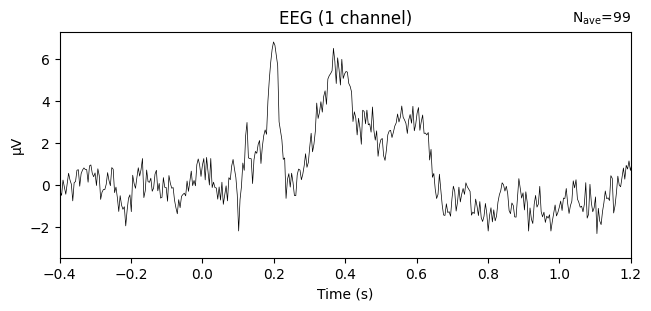

In [7]:
# pick a channel and plot ERP
chan2plot = 'FCz'

fig = erp.plot(picks=chan2plot, xlim=(-0.4, 1.2))

In [19]:
print(type(erp))
print("Channels:", erp.ch_names)
print("Reference:", erp.info['custom_ref_applied'])

idx = erp.time_as_index(0.3)[0]
vals = erp.data[:, idx] * 1e6  # convert V to µV
ranked = sorted(zip(erp.ch_names, vals), key=lambda x: -x[1])
print("Top 5 channels at 0.3 s:")
for ch, v in ranked[:5]:
    print(f"  {ch}: {v:.2f} µV")
print("O1 at 0.3 s:", vals[erp.ch_names.index('O1')], "µV")

<class 'mne.evoked.EvokedArray'>
Channels: ['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2']
Reference: 0 (FIFFV_MNE_CUSTOM_REF_OFF)
Top 5 channels at 0.3 s:
  PO4: 7.79 µV
  PO3: 7.69 µV
  PO8: 7.59 µV
  POz: 6.99 µV
  P6: 6.58 µV
O1 at 0.3 s: 3.662226147912065 µV


In [23]:
erp.times[idx]

np.float64(0.296875)

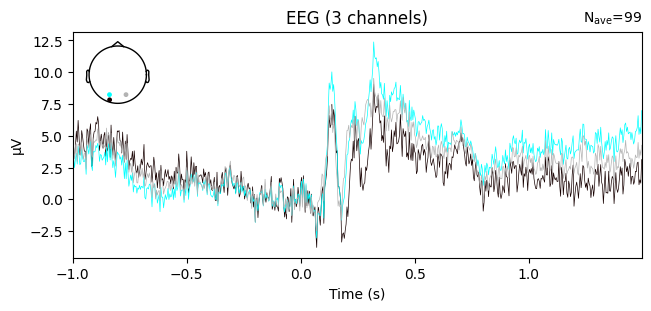

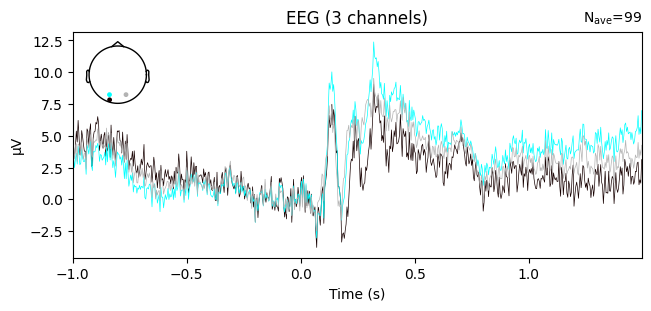

In [22]:
# erp.copy().pick([ranked[0][0]]).plot()
erp.copy().pick(['O1', 'PO3', 'PO4']).plot()

## Plot topographical maps

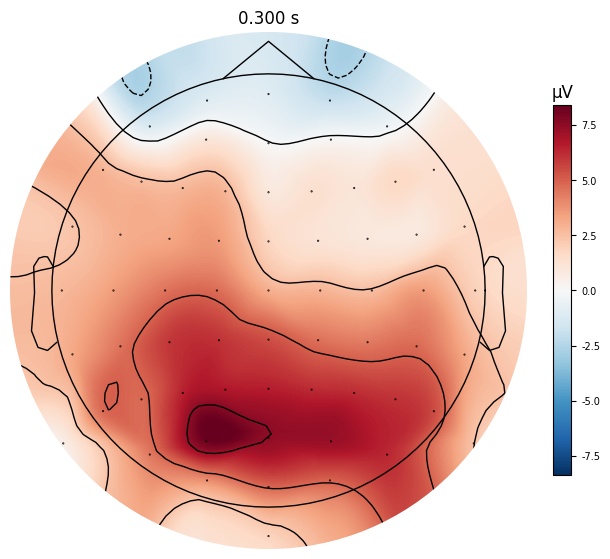

In [17]:
time2plot = 0.3  # in seconds (= 300 ms)

fig = erp.plot_topomap(
    times=time2plot,
    colorbar=True,
    size=4
)

## Now for sample CSD V1 data
This file is not EEG (no channel locations), so we just load it with `loadmat`
and plot with matplotlib.

In [12]:
# load v1_laminar.mat
mat = loadmat('v1_laminar.mat', squeeze_me=True)

# check out the variables in this mat file (like MATLAB's whos)
for key in mat:
    if not key.startswith('__'):
        print(key, np.shape(mat[key]), type(mat[key]))

csd (16, 1527, 200) <class 'numpy.ndarray'>
timevec (1527,) <class 'numpy.ndarray'>
srate () <class 'float'>


In [13]:
csd = mat['csd']
timevec = mat['timevec']

# the data are in variable csd. What is the size? How many channels/time points/trials?
print('csd size (channels x time points x trials):', csd.shape)

csd size (channels x time points x trials): (16, 1527, 200)


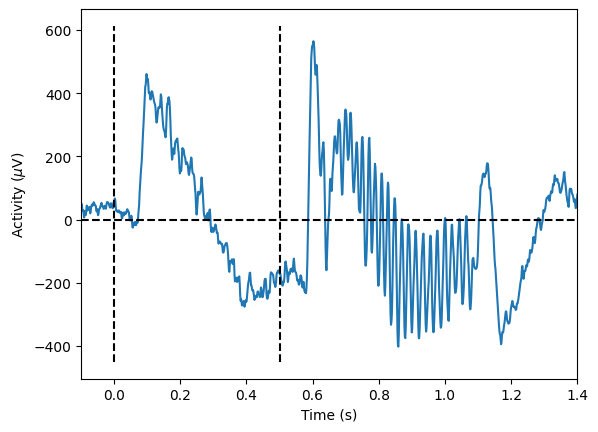

In [14]:
# plot ERP from channel 7 in one line of code!
# (channel 7 in MATLAB = index 6 in Python)
plt.figure(3)
plt.plot(timevec, np.mean(csd[6, :, :], axis=1))
plt.xlim([-.1, 1.4])

ylim = plt.ylim()
plt.plot([-.1, 1.4], [0, 0], 'k--')
plt.plot([0, 0], ylim, 'k--')
plt.plot([0.5, 0.5], ylim, 'k--')
plt.xlabel('Time (s)')
plt.ylabel(r'Activity ($\mu$V)')
plt.show()

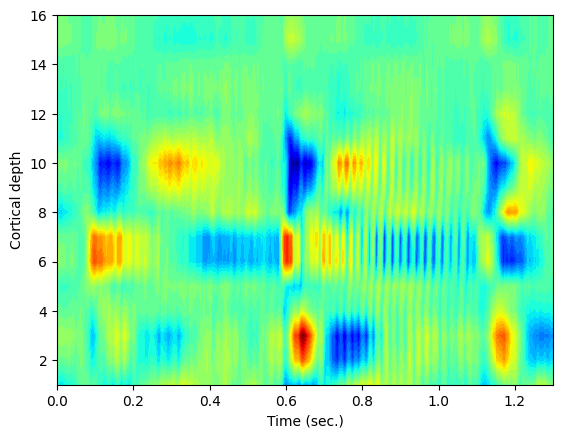

In [15]:
# plot depth-by-time image of ERP by averaging over trials
plt.figure(4)
plt.contourf(timevec, np.arange(1, 17), np.mean(csd, axis=2), 40, cmap='jet')
plt.xlim([0, 1.3])
plt.xlabel('Time (sec.)')
plt.ylabel('Cortical depth')
plt.show()